# 02. BNN prior 기초

TabPFN은 학습용 데이터셋의 절반을 [`01_scm_primer`](01_scm_primer.ipynb)의 SCM prior로, 나머지 절반을 **BNN(Bayesian Neural Network) prior**로 만듭니다(논문 4.4절). BNN prior는 PFN 원 논문(Müller et al., 2022)에서 이미 쓰던 prior입니다. 이 노트북에서는 BNN이 무엇이고, BNN prior가 데이터셋을 어떻게 만들며, SCM prior와 무엇이 다른지를 코드와 그림으로 익힙니다.

다루는 흐름:

1. 신경망 하나 = 함수 하나
2. BNN — 가중치에 분포를 두면 함수의 분포가 된다
3. 하이퍼파라미터가 함수의 모양을 정한다
4. BNN prior로 표 데이터셋 만들기
5. SCM prior와 비교
6. 두 prior 섞기

## `minipfn` 불러오기

다른 노트북과 같은 import shim입니다. 이 노트북은 `notebooks/02_tabpfn/` 아래에 있으므로 저장소 루트는 두 단계 위입니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

5~6절에서 SCM prior와 비교하기 위해, `01_scm_primer` 6절에서 만든 무작위 SCM 샘플러를 `src/minipfn/tabular_prior.py`로 옮겨 두었습니다. 연속 target을 클래스로 바꾸는 `to_classes`(논문 4.5절)와 활성화 함수 목록 `ACTIVATIONS`도 같은 파일에 있습니다.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from minipfn.tabular_prior import (
    ACTIVATIONS,
    sample_random_scm,
    sample_scm_dataset,
    to_classes,
)

# rng = random number generator(난수 생성기). 가중치와 노이즈 등 모든 무작위 값을 여기서 뽑는다.
# 시드 0으로 고정해 실행할 때마다 같은 난수가 나오게 한다.
rng = np.random.default_rng(0)

In [3]:
def draw_dag(ax, edges, pos, colors=None, node_size=900, labels=True, title=None):
    # 01_scm_primer와 같은 그림 도우미. edges: [(원인, 결과), ...], pos: {노드: (x, y)}
    colors = colors or {}
    shrink = np.sqrt(node_size) / 2
    for u, v in edges:
        ax.annotate(
            "",
            xy=pos[v],
            xytext=pos[u],
            arrowprops=dict(arrowstyle="-|>", color="gray", lw=1, shrinkA=shrink, shrinkB=shrink),
        )
    for node, (x, y) in pos.items():
        ax.scatter(x, y, s=node_size, color=colors.get(node, "white"), edgecolor="black", zorder=3)
        if labels:
            ax.text(x, y, node, ha="center", va="center", fontsize=9, zorder=4)
    ax.set_title(title)
    ax.axis("off")
    ax.margins(0.15)

## 1. 신경망 하나 = 함수 하나

신경망(MLP)은 입력 $x$를 받아 층마다 "가중치 곱 + bias → 활성화 함수"를 거쳐 출력 $y$를 냅니다. 가중치가 정해지면 같은 $x$에는 항상 같은 $y$가 나오므로, **가중치가 정해진 신경망 하나는 함수 하나**입니다.

아래 `sample_weights`는 층 크기 목록을 받아 층 사이마다 가중치 행렬과 bias를 뽑고, `mlp_forward`는 그 가중치로 입력을 통과시킵니다.

In [4]:
def sample_weights(layer_sizes, w_std, rng):
    # layer_sizes 예: [1, 16, 16, 1] = 입력 1개 → 은닉 16개 → 은닉 16개 → 출력 1개
    weights = []
    for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:], strict=True):
        # 입력 수로 나눠, 입력이 많아도 다음 층 값의 크기가 비슷하게 유지되도록 한다.
        W = rng.normal(0, w_std / np.sqrt(n_in), (n_in, n_out))
        b = rng.normal(0, 1, n_out)
        weights.append((W, b))
    return weights


def mlp_forward(x, weights, activation, noise_std=0.0, rng=None):
    h = x
    for i, (W, b) in enumerate(weights):
        h = h @ W + b
        is_output_layer = i == len(weights) - 1
        if not is_output_layer:
            h = ACTIVATIONS[activation](h)
        if noise_std > 0:
            # BNN prior는 층마다 노이즈를 더한다 (4절에서 사용).
            h = h + noise_std * rng.standard_normal(h.shape)
    return h

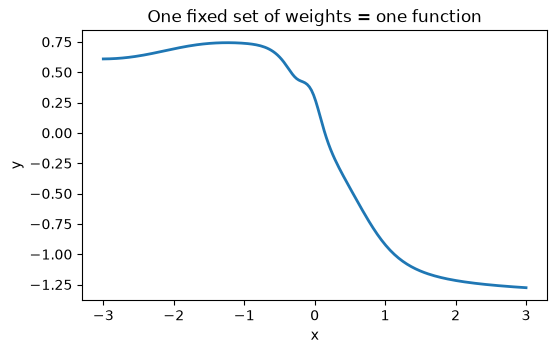

In [5]:
x_grid = np.linspace(-3, 3, 200)[:, None]  # (200, 1): 입력 x 200개
weights = sample_weights([1, 16, 16, 1], w_std=2.0, rng=rng)
y_grid = mlp_forward(x_grid, weights, "tanh")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(x_grid[:, 0], y_grid[:, 0], color="C0", lw=2)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("One fixed set of weights = one function")
plt.show()

## 2. BNN — 가중치에 분포를 두면 함수의 분포가 된다

보통 신경망은 데이터로 가중치 하나를 맞춥니다. **BNN**은 가중치를 하나로 정하지 않고 확률분포로 다룹니다. 데이터를 보기 전의 분포가 prior $p(w)$이고, 여기서는 위의 `sample_weights`처럼 각 가중치를 정규분포에서 뽑는 것이 prior입니다.

가중치를 뽑을 때마다 다른 함수가 나오므로, 가중치의 prior는 곧 **함수에 대한 prior**입니다. [`01_pfn/03`](../01_pfn/03_pfn_implementation_details.ipynb) 8절에서 GP prior로 함수를 뽑았던 것과 같은 일을 신경망으로 하는 셈입니다. PFN 원 논문의 표현으로는 "BNN prior의 task = 가중치가 정해진 신경망 하나"입니다.

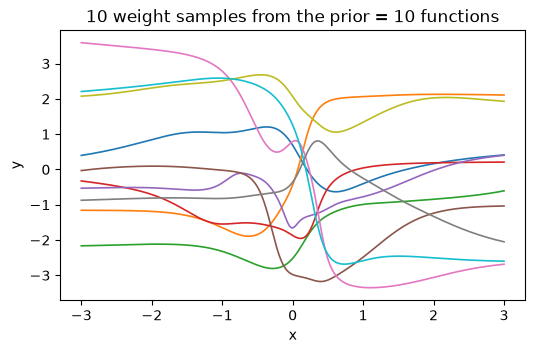

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for _ in range(10):
    weights = sample_weights([1, 16, 16, 1], w_std=2.0, rng=rng)
    ax.plot(x_grid[:, 0], mlp_forward(x_grid, weights, "tanh")[:, 0], lw=1.2)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("10 weight samples from the prior = 10 functions")
plt.show()

데이터 $D$를 보고 나면 가중치에 대한 믿음은 posterior $p(w \mid D)$로 바뀌고, 예측은 posterior 위에서 평균낸 PPD가 됩니다.

$$
p(y \mid x, D) = \int p(y \mid x, w)\; p(w \mid D)\; dw
$$

BNN에서는 이 적분이 닫힌형으로 풀리지 않습니다. 입력이 1개이고 점이 4개뿐이면 무식한 방법으로 근사해 볼 수는 있습니다. prior에서 함수를 5만 개 뽑고, **관측한 점 근처를 모두 지나가는 함수만 남기면** 남은 함수들이 posterior의 근사입니다.

남은 함수: 50000개 중 46개


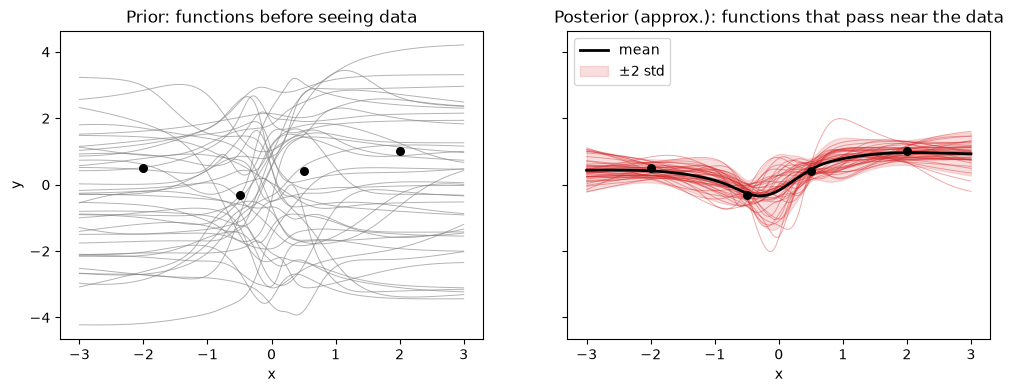

In [7]:
x_obs = np.array([[-2.0], [-0.5], [0.5], [2.0]])
y_obs = np.array([0.5, -0.3, 0.4, 1.0])
tolerance = 0.35  # 관측 점에서 이만큼 안쪽으로 지나가야 남긴다

prior_curves, kept_curves = [], []
for _ in range(50000):
    weights = sample_weights([1, 16, 16, 1], w_std=2.0, rng=rng)
    curve = mlp_forward(x_grid, weights, "tanh")[:, 0]
    at_obs = mlp_forward(x_obs, weights, "tanh")[:, 0]
    prior_curves.append(curve)
    if np.all(np.abs(at_obs - y_obs) < tolerance):
        kept_curves.append(curve)
kept_curves = np.array(kept_curves)
print(f"남은 함수: 50000개 중 {len(kept_curves)}개")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for curve in prior_curves[:40]:
    axes[0].plot(x_grid[:, 0], curve, color="gray", lw=0.7, alpha=0.6)
axes[0].set_title("Prior: functions before seeing data")

for curve in kept_curves:
    axes[1].plot(x_grid[:, 0], curve, color="C3", lw=0.7, alpha=0.4)
mean, std = kept_curves.mean(0), kept_curves.std(0)
axes[1].plot(x_grid[:, 0], mean, color="black", lw=2, label="mean")
axes[1].fill_between(
    x_grid[:, 0], mean - 2 * std, mean + 2 * std, color="C3", alpha=0.15, label="±2 std"
)
axes[1].set_title("Posterior (approx.): functions that pass near the data")
axes[1].legend(loc="upper left")
for ax in axes:
    ax.scatter(x_obs[:, 0], y_obs, color="black", zorder=5, s=30)
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
plt.show()

점 사이에서는 남은 함수들이 좁게 모이고, 점에서 멀어질수록 넓게 퍼집니다. 이 퍼짐이 PPD의 불확실성입니다.

이 방법은 입력 1개, 점 4개라서 겨우 됐습니다. 입력이 여러 개이고 점이 수백 개면 5만 개는커녕 수십억 개를 뽑아도 데이터를 다 지나가는 함수가 거의 남지 않습니다. MCMC나 변분추론으로 근사할 수는 있지만 느립니다. PFN은 이 계산을 하지 않고, BNN prior에서 뽑은 데이터셋으로 학습해서 PPD를 forward pass 한 번으로 근사합니다. PFN 원 논문은 이렇게 학습한 PFN이 BNN posterior를 기존 근사 방법보다 빠르고 정확하게 맞힌다는 것을 보였습니다.

## 3. 하이퍼파라미터가 함수의 모양을 정한다

가중치를 어떤 분포에서 뽑느냐(가중치 표준편차), 활성화 함수가 무엇이냐에 따라 나오는 함수의 모양이 크게 달라집니다. 활성화 함수 4개 × 가중치 표준편차 3개 조합마다 함수를 5개씩 뽑아 봅니다.

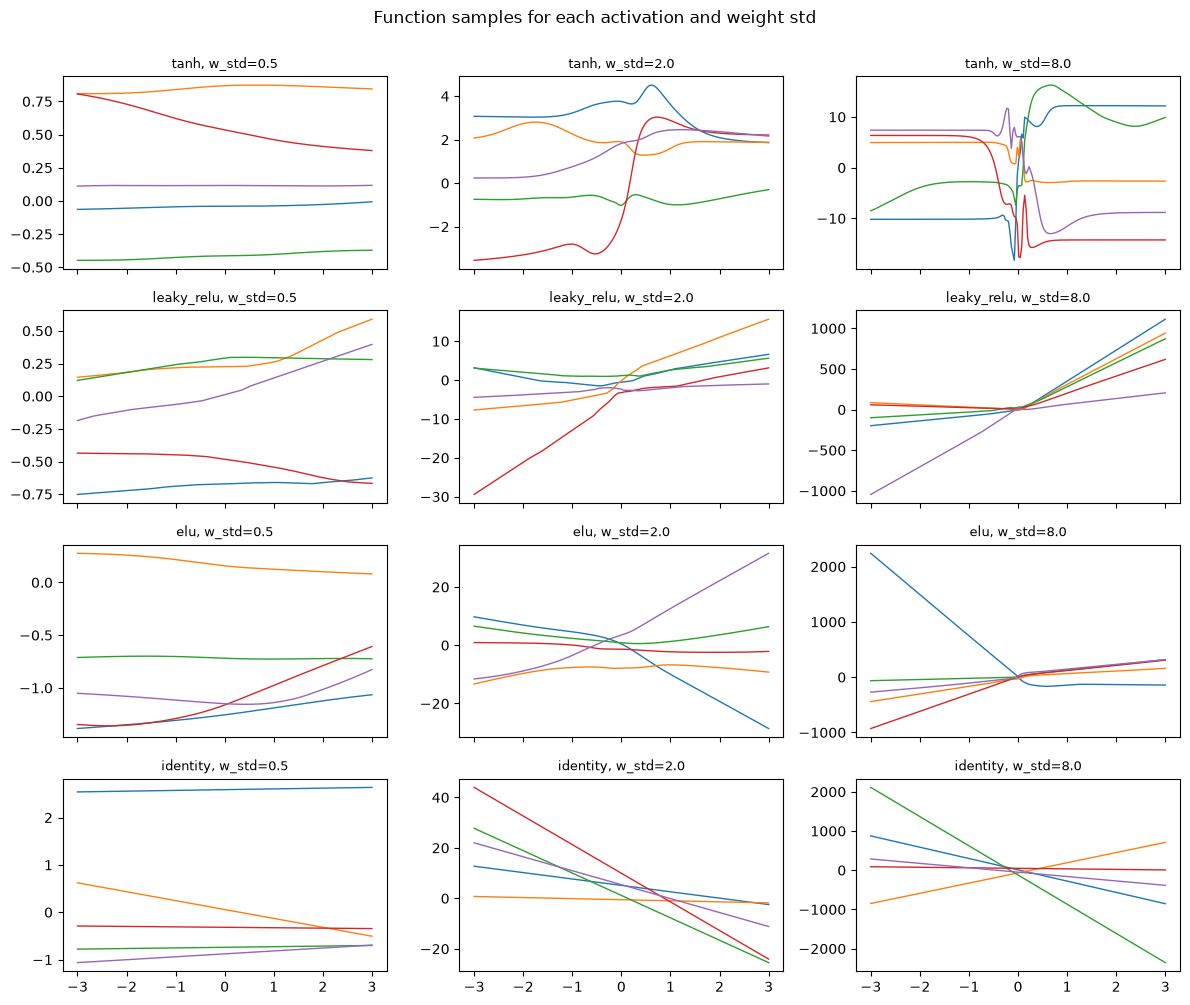

In [8]:
w_stds = [0.5, 2.0, 8.0]
fig, axes = plt.subplots(4, 3, figsize=(12, 10), sharex=True)
for row, activation in enumerate(ACTIVATIONS):
    for col, w_std in enumerate(w_stds):
        ax = axes[row, col]
        for _ in range(5):
            weights = sample_weights([1, 16, 16, 1], w_std=w_std, rng=rng)
            ax.plot(x_grid[:, 0], mlp_forward(x_grid, weights, activation)[:, 0], lw=1)
        ax.set_title(f"{activation}, w_std={w_std}", fontsize=9)
fig.suptitle("Function samples for each activation and weight std", y=1.0)
fig.tight_layout()
plt.show()

identity는 직선만, leaky_relu는 꺾은선, tanh와 elu는 부드러운 곡선을 만들고, 가중치 표준편차가 클수록 함수가 급하게 변합니다. 어떤 조합이 현실 데이터에 맞을지 미리 알 수 없으므로, TabPFN은 하이퍼파라미터 하나를 고르지 않고 **하이퍼파라미터도 분포에서 뽑습니다**. 데이터셋마다 먼저 하이퍼파라미터를 뽑고, 그 하이퍼파라미터로 가중치를 뽑습니다.

논문 4.1절은 이것을 "prior의 하이퍼파라미터에 대해서도 완전히 베이지안이 된다"고 표현합니다. 하이퍼파라미터를 하나로 고정하지 않았으므로, PFN이 근사하는 PPD는 가중치뿐 아니라 신경망 구조와 하이퍼파라미터까지 함께 적분한 것이 됩니다.

부록 E.4의 MLP 하이퍼파라미터와, 이 노트북에서 단순화한 값은 다음과 같습니다.

| 하이퍼파라미터 | 논문 (부록 E.4) | 이 노트북 (4절) |
|---|---|---|
| 은닉층 수 | 대략 2~6, 작은 값이 더 자주 | 1~3 |
| 층당 노드 수 | 대략 4~130, 작은 값이 더 자주 | 4~32 (로그 스케일) |
| 가중치 표준편차 | 대략 0.01~10 | 0.3~3 (로그 스케일) |
| 노이즈 표준편차 | 대략 0.0001~0.3 | 0.001~0.3 (로그 스케일) |
| 활성화 함수 | tanh, LeakyReLU, ELU, identity 중 하나 | 같음 |
| 가중치 dropout | $0.9 \cdot \mathrm{Beta}(a, b)$ | 생략 |

## 4. BNN prior로 표 데이터셋 만들기

논문 4.4절은 BNN prior의 데이터셋 생성 절차를 이렇게 설명합니다. *"먼저 신경망 구조와 가중치를 뽑는다. 그다음 데이터셋의 행마다 입력 $x$를 뽑고, 노이즈를 더해 가며 BNN에 통과시킨 출력 $y$를 target으로 쓴다."*

### 작은 예로 먼저 보기

입력 2개 → 은닉 노드 3개 → 출력 1개짜리 작은 BNN으로 이 절차를 따라가 봅니다. 01의 SCM 예와 같은 두 단계로 볼 수 있습니다.

1. 모든 노드의 값을 계산합니다.
2. 열 몇 개만 남깁니다.

차이는 어떤 열을 남기는지가 **정해져 있다**는 점입니다. BNN prior에서는 항상 입력층이 feature $x$이고 출력층이 target $y$이며, 은닉층은 버립니다. 예측용 MLP를 그릴 때의 익숙한 모습과 같습니다.

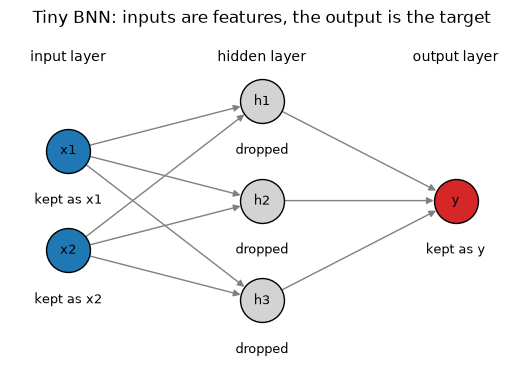

In [9]:
pos = {
    "x1": (0, 0.5),
    "x2": (0, -0.5),
    "h1": (1, 1),
    "h2": (1, 0),
    "h3": (1, -1),
    "y": (2, 0),
}
edges = [(x, h) for x in ["x1", "x2"] for h in ["h1", "h2", "h3"]]
edges += [(h, "y") for h in ["h1", "h2", "h3"]]
colors = {
    "x1": "C0",
    "x2": "C0",
    "h1": "lightgray",
    "h2": "lightgray",
    "h3": "lightgray",
    "y": "C3",
}

fig, ax = plt.subplots(figsize=(6.5, 4.4))
draw_dag(ax, edges, pos, colors, node_size=1000)
for node, (x, y) in pos.items():
    role = {"x1": "kept as x1", "x2": "kept as x2", "y": "kept as y"}.get(node, "dropped")
    ax.text(x, y - 0.42, role, ha="center", va="top", fontsize=9)
for k, name in enumerate(["input layer", "hidden layer", "output layer"]):
    ax.text(k, 1.4, name, ha="center", fontsize=10)
ax.set_ylim(-1.7, 1.7)
ax.set_title("Tiny BNN: inputs are features, the output is the target")
plt.show()

**1단계: 모든 노드를 계산합니다.** 가중치는 데이터셋 하나에 한 번만 뽑고, 입력 $x$는 행마다 새로 뽑습니다. 노이즈는 은닉층과 출력층에 더합니다.

In [10]:
noise_std = 0.1

# (1) 데이터셋마다 한 번: 가중치를 뽑는다.
tiny_weights = sample_weights([2, 3, 1], w_std=2.0, rng=rng)
(W1, b1), (W2, b2) = tiny_weights

# (2) 행마다: 입력 x를 뽑는다. 여기서는 5행.
x = rng.standard_normal((5, 2))

# (3) 층 순서대로 계산한다: 은닉층 → 출력층
h = np.tanh(x @ W1 + b1) + noise_std * rng.standard_normal((5, 3))
y_cont = h @ W2 + b2 + noise_std * rng.standard_normal((5, 1))

all_nodes = pd.DataFrame(
    np.column_stack([x, h, y_cont]), columns=["x1", "x2", "h1", "h2", "h3", "y"]
).round(2)
all_nodes

,x1,x2,h1,h2,h3,y
0,0.18,-1.45,-0.99,-0.91,-0.59,-0.00
1,2.02,1.02,1.07,-1.10,0.87,-0.20
2,-0.12,-1.41,-1.01,-0.46,-0.70,-0.10
3,1.52,0.70,1.02,-1.01,0.89,-0.22
4,-0.44,2.77,1.07,-0.69,1.12,0.13


**2단계: 입력과 출력 열만 남깁니다.** 은닉 노드 h1~h3는 버립니다. 마지막으로 01과 같은 `to_classes`로 연속값 y를 클래스로 바꾸면 분류 데이터셋이 됩니다.

In [11]:
dataset = all_nodes[["x1", "x2", "y"]].copy()
dataset["y (class)"] = to_classes(dataset["y"].to_numpy(), max_classes=3, rng=rng)
dataset

,x1,x2,y,y (class)
0,0.18,-1.45,-0.00,0
1,2.02,1.02,-0.20,1
2,-0.12,-1.41,-0.10,0
3,1.52,0.70,-0.22,1
4,-0.44,2.77,0.13,0


### 무작위 BNN으로 데이터셋 뽑기

위 절차에서 하이퍼파라미터(은닉층 수, 노드 수, 활성화 함수, 가중치와 노이즈의 표준편차)까지 무작위로 뽑으면 BNN prior의 샘플러가 됩니다. 단계마다 주석을 달았습니다.

In [12]:
def sample_bnn_dataset(n_features, n_samples, max_classes, rng):
    # 1) 하이퍼파라미터를 뽑는다. 작은 값이 더 자주 나오도록 로그 스케일에서 뽑는다.
    n_hidden_layers = int(rng.integers(1, 4))
    hidden = int(np.exp(rng.uniform(np.log(4), np.log(32))))
    activation = str(rng.choice(list(ACTIVATIONS)))
    w_std = np.exp(rng.uniform(np.log(0.3), np.log(3)))
    noise_std = np.exp(rng.uniform(np.log(1e-3), np.log(0.3)))

    # 2) 가중치를 뽑는다. 입력층 크기 = feature 수, 출력층 크기 = 1(target).
    layer_sizes = [n_features] + [hidden] * n_hidden_layers + [1]
    weights = sample_weights(layer_sizes, w_std, rng)

    # 3) 행마다 입력 x를 뽑아, 노이즈를 더해 가며 신경망에 통과시킨다.
    x = rng.standard_normal((n_samples, n_features))
    y_cont = mlp_forward(x, weights, activation, noise_std, rng)[:, 0]

    # 4) 연속 target을 클래스로 바꾼다 (4.5절).
    y = to_classes(y_cont, max_classes, rng)
    info = {"layers": n_hidden_layers, "hidden": hidden, "activation": activation}
    return x, y, info

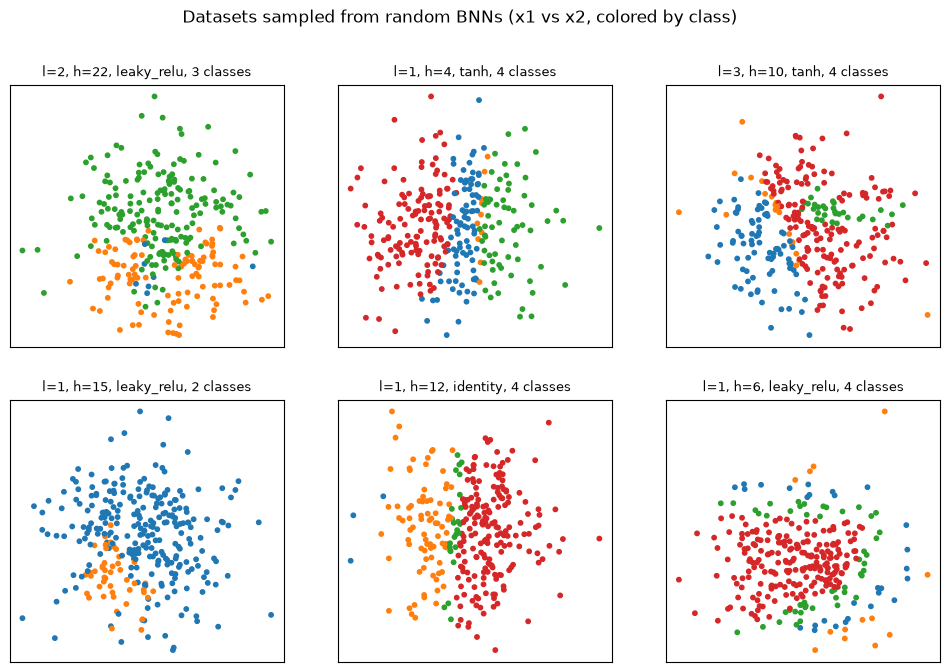

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
for ax in axes.flat:
    x, y, info = sample_bnn_dataset(n_features=2, n_samples=300, max_classes=4, rng=rng)
    ax.scatter(x[:, 0], x[:, 1], c=y, cmap="tab10", vmin=0, vmax=9, s=10)
    ax.set_title(
        f"l={info['layers']}, h={info['hidden']}, {info['activation']}, {y.max() + 1} classes",
        fontsize=9,
    )
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Datasets sampled from random BNNs (x1 vs x2, colored by class)")
plt.show()

01에서 본 SCM 데이터셋과 비교하면 두 가지가 눈에 띕니다. 점들이 둥근 덩어리 모양으로 고르게 퍼져 있고(입력을 표준정규분포에서 독립으로 뽑았기 때문), 클래스 경계가 비교적 뚜렷한 데이터셋이 많습니다. 5절에서 이 차이를 숫자로 확인합니다.

## 5. SCM prior와 비교

두 prior 모두 "MLP 모양의 그래프로 값을 계산한 뒤 열 몇 개를 남긴다"는 점은 같습니다. 다른 점은 **어떤 열을 남기느냐**입니다.

| | SCM prior (01) | BNN prior |
|---|---|---|
| feature $x$ | 그래프의 아무 노드 | 항상 입력층 |
| target $y$ | 그래프의 아무 노드 | 항상 출력층 |
| feature가 target의 결과일 수 있나 | 있다 | 없다 (항상 원인 쪽) |
| 표에 없는 원인 | 있다 (버린 노드가 target에 영향) | 없다 (target은 x와 노이즈로만 정해짐) |
| feature끼리의 상관 | 공통 원인을 공유하면 생긴다 | 없다 (입력을 독립으로 뽑음) |

이 차이가 실제 데이터셋에서 어떻게 드러나는지 두 가지로 재 봅니다. 각 prior에서 데이터셋을 200개씩 뽑습니다.

- **예측 가능성**: feature로 클래스를 얼마나 맞힐 수 있는가. 01과 같은 "kNN 교차검증 정확도 − 가장 많은 클래스의 비율"(gain)입니다.
- **feature 간 상관**: feature 5개짜리 데이터셋에서 feature 쌍의 상관계수 절댓값 평균입니다.

In [14]:
import warnings

from sklearn.model_selection import KFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier

warnings.filterwarnings("ignore", category=UserWarning)  # 아주 작은 클래스에 대한 경고는 숨긴다


def predictability_gain(x, y):
    acc = cross_val_score(KNeighborsClassifier(15), x, y, cv=KFold(3, shuffle=True, random_state=0))
    return acc.mean() - np.bincount(y).max() / len(y)


def mean_abs_feature_corr(x):
    corr = np.corrcoef(x.T)
    upper = corr[np.triu_indices(x.shape[1], k=1)]  # 대각선 위쪽 = feature 쌍마다 하나
    return np.nan_to_num(np.abs(upper)).mean()


def sample_scm(n_features):
    scm = sample_random_scm(n_features, rng)
    return sample_scm_dataset(scm, n_samples=300, max_classes=4, rng=rng)


def sample_bnn(n_features):
    x, y, _ = sample_bnn_dataset(n_features, n_samples=300, max_classes=4, rng=rng)
    return x, y


results = {}
for name, sampler in {"SCM": sample_scm, "BNN": sample_bnn}.items():
    gains = [predictability_gain(*sampler(2)) for _ in range(200)]
    corrs = [mean_abs_feature_corr(sampler(5)[0]) for _ in range(200)]
    results[name] = (np.array(gains), np.array(corrs))

pd.DataFrame(
    {
        "gain > 0.15 비율": [np.mean(results[k][0] > 0.15) for k in results],
        "gain < 0.05 비율": [np.mean(results[k][0] < 0.05) for k in results],
        "feature 간 |상관| 평균": [results[k][1].mean() for k in results],
    },
    index=list(results),
).round(2)

,gain > 0.15 비율,gain < 0.05 비율,feature 간 |상관| 평균
SCM,0.15,0.71,0.28
BNN,0.55,0.26,0.05


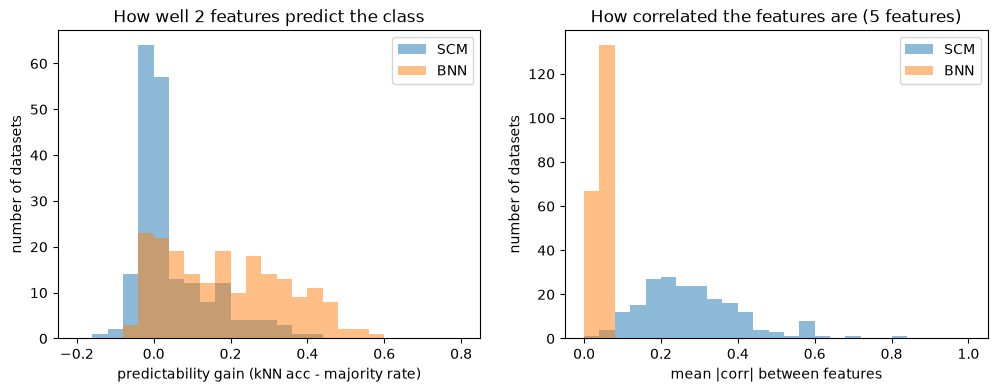

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins_gain = np.linspace(-0.2, 0.8, 26)
bins_corr = np.linspace(0, 1, 26)
for name, color in [("SCM", "C0"), ("BNN", "C1")]:
    gains, corrs = results[name]
    axes[0].hist(gains, bins=bins_gain, alpha=0.5, color=color, label=name)
    axes[1].hist(corrs, bins=bins_corr, alpha=0.5, color=color, label=name)
axes[0].set_xlabel("predictability gain (kNN acc - majority rate)")
axes[0].set_title("How well 2 features predict the class")
axes[1].set_xlabel("mean |corr| between features")
axes[1].set_title("How correlated the features are (5 features)")
for ax in axes:
    ax.set_ylabel("number of datasets")
    ax.legend()
plt.show()

BNN 데이터셋은 target이 feature와 노이즈로만 정해지므로 feature로 클래스를 맞히기 쉽고, feature끼리는 거의 상관이 없습니다. SCM 데이터셋은 보이지 않는 원인 때문에 맞히기 어려운 경우가 많고, feature끼리 상관된 경우가 흔합니다.

현실의 표 데이터는 feature끼리 상관된 경우가 많고, 표에 없는 요인이 target에 영향을 주는 경우도 흔합니다. 그 점에서 SCM prior가 현실에 더 가깝습니다. 논문의 ablation(부록 B.4)도 이와 맞는 결과를 보여 줍니다. 테스트 데이터셋에서 prior별로 TabPFN을 학습해 비교한 결과입니다.

| 학습에 쓴 prior | 평균 cross-entropy (낮을수록 좋음) | 평균 ROC AUC (높을수록 좋음) |
|---|---|---|
| BNN만 | 0.811 | 0.865 |
| SCM만 | 0.771 | 0.881 |
| SCM + BNN | 0.776 | 0.883 |

SCM만 쓴 것과 둘을 섞은 것은 거의 같고, BNN만 쓰면 눈에 띄게 나쁩니다. 논문도 "BNN과 SCM prior를 섞는 것은 순수 SCM prior와 큰 차이가 없어 보인다"고 적었습니다.

## 6. 두 prior 섞기

TabPFN은 학습할 때 데이터셋을 하나 만들 때마다 동전을 던져, 같은 확률로 SCM prior 또는 BNN prior를 고릅니다(4.4절). 코드로는 다음과 같습니다.

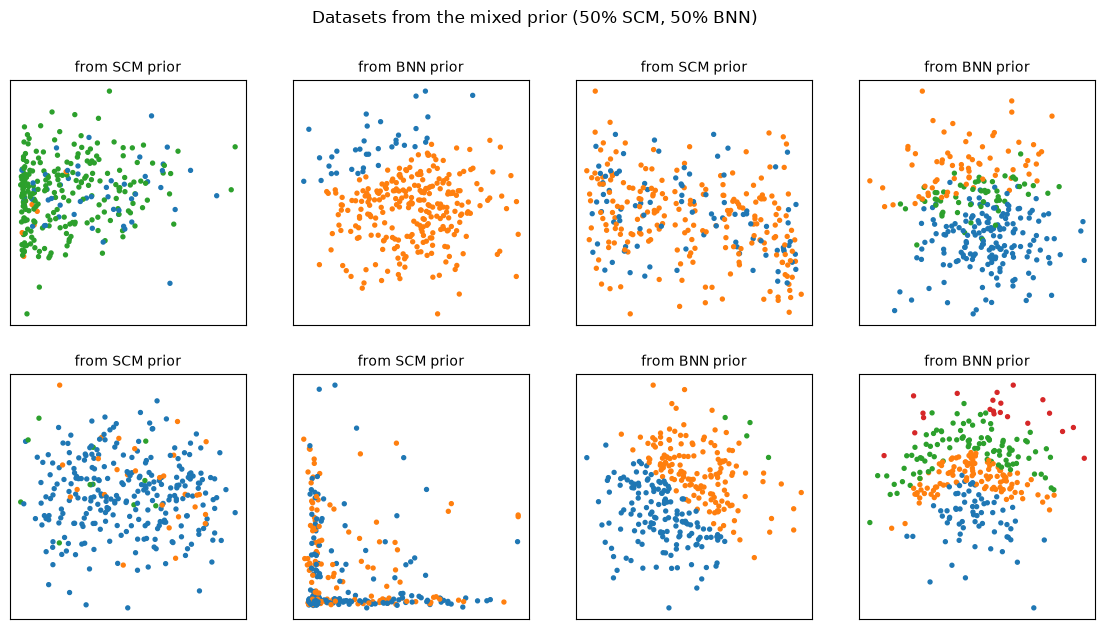

In [16]:
def sample_tabpfn_prior_dataset(n_features, rng):
    # 동전 던지기: 반반 확률로 두 prior 중 하나를 고른다.
    if rng.random() < 0.5:
        x, y = sample_scm(n_features)
        return x, y, "SCM"
    x, y, _ = sample_bnn_dataset(n_features, n_samples=300, max_classes=4, rng=rng)
    return x, y, "BNN"


fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax in axes.flat:
    x, y, source = sample_tabpfn_prior_dataset(n_features=2, rng=rng)
    ax.scatter(x[:, 0], x[:, 1], c=y, cmap="tab10", vmin=0, vmax=9, s=8)
    ax.set_title(f"from {source} prior", fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Datasets from the mixed prior (50% SCM, 50% BNN)")
plt.show()

어느 prior에서 나왔든 결과는 같은 형식의 표(feature 열 + 클래스 열)이므로, PFN에는 [`01_scm_primer`](01_scm_primer.ipynb) 6절에서 본 방식 그대로 들어갑니다. 학습 행은 y까지 보여 주고, 테스트 행은 y를 `?`로 가린 채 넣어 `?` 자리의 클래스 분포를 예측합니다. PFN은 지금 받은 표가 어느 prior에서 나왔는지 듣지 못합니다. 학습 행만 보고 어느 쪽에 가까운지까지 암묵적으로 따져서 예측해야 하고, 이것이 3절에서 말한 "하이퍼파라미터까지 적분한 PPD"의 의미입니다.

## 7. 정리

| 개념 | 이 노트북 | TabPFN에서 |
|---|---|---|
| 신경망 하나 | 가중치가 정해진 MLP = 함수 하나 | BNN prior의 task 하나 |
| BNN | 가중치에 prior $p(w)$를 둔 신경망 = 함수의 분포 | 데이터셋을 만드는 생성 과정 |
| posterior, PPD | 점 근처를 지나는 함수만 남겨 근사 | 직접 계산하지 않고 PFN이 근사 |
| 하이퍼파라미터 | 활성화 함수·가중치 크기가 함수 모양을 정함 | 하이퍼파라미터도 분포에서 뽑음 (4.1절) |
| BNN 데이터셋 | 입력층 = feature, 출력층 = target | `sample_bnn_dataset` |
| SCM과의 차이 | 맞히기 쉽고 feature끼리 상관 없음 | SCM만 쓴 것이 BNN만 쓴 것보다 좋음 (B.4) |
| 섞기 | 동전 던지기로 둘 중 하나 | SCM 50% + BNN 50% |